# 네이트 카테크 전기차 리스트 크롤링

- 출처: https://cartech.nate.com/page/carPopular/elec (인기 차종 → **전기차** 탭)
- 목표: 전기차 목록(브랜드, 모델, 연식, 전비, 월 렌트료)을 표(DataFrame)로 만들고 CSV로 저장하기

## 1. 라이브러리 불러오기

In [2]:
import re
import requests
import pandas as pd
from bs4 import BeautifulSoup

## 2. 페이지 가져오기

전기차 탭은 한 페이지에 다 안 나오고 **'더 보기'** 버튼으로 나머지를 불러옵니다.
'더 보기'는 주소 뒤에 `search[limit][offset]=1, 2, ...` 를 붙여 요청하는 방식이라, 페이지 번호를 바꿔가며 모두 가져옵니다.

In [3]:
URL = "https://cartech.nate.com/page/carPopular/elec"
HEADERS = {"User-Agent": "Mozilla/5.0"}

def get_page(offset):
    res = requests.get(URL, params={"search[limit][offset]": offset}, headers=HEADERS)
    res.raise_for_status()
    return BeautifulSoup(res.text, "html.parser")

# 첫 페이지에서 전체 페이지 수(data-pages)와 차량 수(data-total) 확인
first = get_page(0)
pane = first.select_one('.cpTabPane[data-tab="elec"]')
pages = int(pane["data-pages"])
total = int(pane["data-total"])
print("전체 페이지 수:", pages, "/ 전체 차량 수:", total)

전체 페이지 수: 2 / 전체 차량 수: 14


## 3. 차량 정보 뽑기

In [4]:
def parse_cars(soup):
    cars = []
    for item in soup.select('.cpTabPane[data-tab="elec"] .popularResultCon > .list'):
        name_tag = item.select_one(".name")
        brand = name_tag.select_one(".mobile").get_text(strip=True)
        name_tag.select_one(".mobile").extract()          # 브랜드 글자를 빼고 모델명만 남김
        model = name_tag.get_text(strip=True)              # 예: 'EV3 2026년형'

        info = item.select_one(".info p")
        info_text = info.get_text("|", strip=True) if info else ""

        cars.append({
            "순위": int(item.select_one(".rank").get_text(strip=True)),
            "브랜드": brand,
            "모델": model,
            "계약기간": item.select_one(".month").get_text(strip=True),
            "정보": info_text,
            "월렌트료": item.select_one(".price h2").get_text(strip=True),
            "이미지": "https://cartech.nate.com" + item.select_one("img")["src"],
        })
    return cars

rows = parse_cars(first)
for offset in range(1, pages):
    rows += parse_cars(get_page(offset))

df = pd.DataFrame(rows)
print(len(df), "대 수집")
df

14 대 수집


,순위,브랜드,모델,계약기간,정보,월렌트료,이미지
0,1,BYD,Dolphin 2026년형,36개월,복합 5.1km/kWh|전기,상담문의,https://cartech.nate.com/data//car/82/16/82163...
1,2,BYD,SEALION 7 2027년형,36개월,복합 4.3km/kWh|전기,상담문의,https://cartech.nate.com/data//car/8d/83/8d832...
2,3,테슬라,New Model Y 2026년형,36개월,복합 5.6km/kWh|전기,상담문의,https://cartech.nate.com/data//car/ce/ad/cead0...
3,4,테슬라,Model 3 2026년형,36개월,복합 5.4km/kWh|전기,상담문의,https://cartech.nate.com/data//car/12/d3/12d3e...
4,5,기아,EV3 2026년형,36개월,복합 5.2km/kWh|전기,"월132,604원~",https://cartech.nate.com/data//car/d3/b7/d3b72...
5,6,현대,캐스퍼 일렉트릭 2026년형,36개월,복합 5.6km/kWh|전기,"월139,810원~",https://cartech.nate.com/data//car/f2/55/f2552...
6,7,기아,EV6 2027년형,36개월,복합 5.3km/kWh|전기,"월252,817원~",https://cartech.nate.com/data//car/c9/2c/c92c8...
7,8,아우디,Q4 e-tron 2022년형,36개월,82kWh|복합 4.3km/kWh|전기,"월904,900원~",https://cartech.nate.com/data//car/6d/37/6d370...
8,9,벤츠,EQA(구식) 2023년형,36개월,66.5kWh|복합 4.9km/kWh|전기,"월1,024,040원~",https://cartech.nate.com/data//car/3d/c0/3dc06...
9,10,BMW,i4 2023년형,36개월,전기,"월1,158,853원~",https://cartech.nate.com/data//car/52/e8/52e8b...


## 4. 데이터 정리

- `모델`에서 연식(예: 2026년형)을 따로 분리
- `정보`에서 전비(km/kWh)와 배터리 용량(kWh)을 숫자로 분리
- `월렌트료`를 숫자로 바꾸기 ('상담문의'는 빈 값)

In [5]:
df["연식"] = df["모델"].str.extract(r"(\d{4})년형").astype("Int64")
df["모델"] = df["모델"].str.replace(r"\s*\d{4}년형", "", regex=True)

df["전비(km/kWh)"] = df["정보"].str.extract(r"복합\s*([\d.]+)km/kWh").astype(float)
df["배터리(kWh)"] = df["정보"].str.extract(r"(?:^|\|)([\d.]+)kWh").astype(float)

df["월렌트료(원)"] = pd.to_numeric(
    df["월렌트료"].str.replace(r"[^\d]", "", regex=True), errors="coerce"
).astype("Int64")

df = df[["순위", "브랜드", "모델", "연식", "전비(km/kWh)", "배터리(kWh)", "계약기간", "월렌트료(원)", "이미지"]]
df

,순위,브랜드,모델,연식,전비(km/kWh),배터리(kWh),계약기간,월렌트료(원),이미지
0,1,BYD,Dolphin,2026,5.1,NaN,36개월,<NA>,https://cartech.nate.com/data//car/82/16/82163...
1,2,BYD,SEALION 7,2027,4.3,NaN,36개월,<NA>,https://cartech.nate.com/data//car/8d/83/8d832...
2,3,테슬라,New Model Y,2026,5.6,NaN,36개월,<NA>,https://cartech.nate.com/data//car/ce/ad/cead0...
3,4,테슬라,Model 3,2026,5.4,NaN,36개월,<NA>,https://cartech.nate.com/data//car/12/d3/12d3e...
4,5,기아,EV3,2026,5.2,NaN,36개월,132604,https://cartech.nate.com/data//car/d3/b7/d3b72...
5,6,현대,캐스퍼 일렉트릭,2026,5.6,NaN,36개월,139810,https://cartech.nate.com/data//car/f2/55/f2552...
6,7,기아,EV6,2027,5.3,NaN,36개월,252817,https://cartech.nate.com/data//car/c9/2c/c92c8...
7,8,아우디,Q4 e-tron,2022,4.3,82.0,36개월,904900,https://cartech.nate.com/data//car/6d/37/6d370...
8,9,벤츠,EQA(구식),2023,4.9,66.5,36개월,1024040,https://cartech.nate.com/data//car/3d/c0/3dc06...
9,10,BMW,i4,2023,NaN,NaN,36개월,1158853,https://cartech.nate.com/data//car/52/e8/52e8b...


## 5. 간단히 살펴보기

In [6]:
print("브랜드별 차량 수")
print(df["브랜드"].value_counts())

print("\n전비가 좋은 순 TOP 5")
print(df.sort_values("전비(km/kWh)", ascending=False)[["브랜드", "모델", "전비(km/kWh)"]].head())

print("\n월렌트료가 공개된 차량 (싼 순)")
print(df.dropna(subset=["월렌트료(원)"]).sort_values("월렌트료(원)")[["브랜드", "모델", "월렌트료(원)"]])

브랜드별 차량 수
브랜드
기아      3
BYD     2
테슬라     2
폭스바겐    2
현대      1
아우디     1
벤츠      1
BMW     1
폴스타     1
Name: count, dtype: int64

전비가 좋은 순 TOP 5
    브랜드           모델  전비(km/kWh)
2   테슬라  New Model Y         5.6
5    현대     캐스퍼 일렉트릭         5.6
3   테슬라      Model 3         5.4
10   기아          EV4         5.4
6    기아          EV6         5.3

월렌트료가 공개된 차량 (싼 순)
   브랜드         모델  월렌트료(원)
4   기아        EV3   132604
5   현대   캐스퍼 일렉트릭   139810
6   기아        EV6   252817
7  아우디  Q4 e-tron   904900
8   벤츠    EQA(구식)  1024040
9  BMW         i4  1158853


## 6. CSV로 저장

In [7]:
df.to_csv("cartech_전기차_리스트.csv", index=False, encoding="utf-8-sig")  # 엑셀에서 한글 안 깨지게 utf-8-sig
print("저장 완료: cartech_전기차_리스트.csv")

저장 완료: cartech_전기차_리스트.csv


---
# 질문 1. 날짜별로 기사가 몇 개씩 올라왔어? 늘고 있어, 줄고 있어?

- 출처: https://cartech.nate.com/page/news/ (8개 탭: 최신·신차·업계·시승기·기획·퍼스트룩·인터뷰·칼럼)
- 주의: 탭마다 **최신 기사 약 16개만** 보여줘서, 오래된 날짜일수록 실제보다 적게 잡혀요.
  그래서 추세는 최근 두 달(9~10월) 위주로 봅니다.
- 뉴스 페이지는 계속 바뀌므로 2026-10-29에 저장한 스냅샷 파일(`cartech_뉴스_스냅샷_2026-10-29.html`)로 분석합니다.

## 1-1. 뉴스 페이지에서 기사 모으기

In [8]:
import os

# 뉴스 페이지는 계속 바뀌어서, 한 번 저장한 파일(스냅샷)을 읽어 결과가 매번 같게 함
# 최신 기사로 다시 분석하려면 이 파일을 지우고 실행하면 새로 받아서 저장함
NEWS_FILE = "cartech_뉴스_스냅샷_2026-10-29.html"
if os.path.exists(NEWS_FILE):
    html = open(NEWS_FILE, encoding="utf-8").read()
else:
    html = requests.get("https://cartech.nate.com/page/news/", headers=HEADERS).text
    open(NEWS_FILE, "w", encoding="utf-8").write(html)
news_soup = BeautifulSoup(html, "html.parser")

news_rows = []
for tab in news_soup.select(".nTabContent"):                       # 탭 8개
    for a in tab.select('a[href*="/board/nateNews/view/"]'):        # 탭 안의 기사 링크
        dates = [x.get_text(strip=True) for x in a.select(".date")]
        date = [d for d in dates if re.fullmatch(r"\d{4}\.\d{2}\.\d{2}", d)]
        title = a.select_one("h2, h3, h4")
        news_rows.append({
            "탭": tab.get("id"),
            "날짜": date[0] if date else None,
            "제목": title.get_text(strip=True) if title else "",
            "링크": "https://cartech.nate.com" + a["href"],
        })

news = pd.DataFrame(news_rows).dropna(subset=["날짜"])
news = news.drop_duplicates("링크")          # 여러 탭에 같은 기사가 겹치므로 중복 제거
news["날짜"] = pd.to_datetime(news["날짜"])
print("중복 제거 후 기사 수:", len(news))
news.sort_values("날짜", ascending=False).head(10)

중복 제거 후 기사 수: 111


,탭,날짜,제목,링크
0,mNewsRecent,2026-10-29,"애스턴마틴, 지붕 여는 하이브리드 슈퍼카 공개",https://cartech.nate.com/board/nateNews/view/e...
1,mNewsRecent,2026-10-29,"HS효성더클래스, 아우스빌둥 도장 부문 1·2위 배출",https://cartech.nate.com/board/nateNews/view/d...
2,mNewsRecent,2026-10-29,"한국타이어, 2026 한국품질만족지수 두 개 부문 1위 석권",https://cartech.nate.com/board/nateNews/view/1...
3,mNewsRecent,2026-10-29,"롤스로이스, 실버 고스트 탄생 120주년 기념",https://cartech.nate.com/board/nateNews/view/6...
4,mNewsRecent,2026-10-29,"제네시스, GV90 테크 데이서 플래그십 핵심 기술 개발 과정 공개",https://cartech.nate.com/board/nateNews/view/6...
5,mNewsRecent,2026-10-28,"람보르기니 서울 10년, 10개의 이야기",https://cartech.nate.com/board/nateNews/view/1...
6,mNewsRecent,2026-10-28,"HS효성더클래스, 간송미술관서 마스테리아 아트 프로그램 개최",https://cartech.nate.com/board/nateNews/view/b...
7,mNewsRecent,2026-10-28,"한성자동차, 2026 마이바흐 고객 인비테이셔널 성료",https://cartech.nate.com/board/nateNews/view/b...
12,mNewsRecent,2026-10-28,"벤츠, 디 올-뉴 일렉트릭 GLB 사전계약 시작",https://cartech.nate.com/board/nateNews/view/f...
13,mNewsRecent,2026-10-28,"렉서스, 로드 앤 메모리 가을 시즌 어메이징 패션 성료",https://cartech.nate.com/board/nateNews/view/0...


## 1-2. 날짜별 기사 수

In [9]:
daily = news.groupby(news["날짜"].dt.date).size().rename("기사 수")
daily[daily.index >= pd.Timestamp("2026-09-01").date()]

날짜
2026-09-03    1
2026-09-05    1
2026-09-06    1
2026-09-13    1
2026-09-18    1
2026-09-19    1
2026-09-21    1
2026-09-23    1
2026-09-25    1
2026-09-27    1
2026-09-28    1
2026-09-29    1
2026-09-30    1
2026-10-01    1
2026-10-02    8
2026-10-03    1
2026-10-04    1
2026-10-05    1
2026-10-06    3
2026-10-07    1
2026-10-08    1
2026-10-10    1
2026-10-12    2
2026-10-13    3
2026-10-19    2
2026-10-20    3
2026-10-21    3
2026-10-22    1
2026-10-23    1
2026-10-26    1
2026-10-27    5
2026-10-28    6
2026-10-29    5
Name: 기사 수, dtype: int64

## 1-3. 주별 · 월별 기사 수 (추세 보기)

In [10]:
weekly = news[news["날짜"] >= "2026-08-31"].set_index("날짜").resample("W-SUN").size().rename("기사 수")
weekly.index = [f"{(d - pd.Timedelta(days=6)).strftime('%m/%d')} ~ {d.strftime('%m/%d')}" for d in weekly.index]
print("[주별]")
print(weekly.to_string())

monthly = news.groupby(news["날짜"].dt.to_period("M")).size().rename("기사 수")
print("\n[월별]")
print(monthly.to_string())

[주별]
08/31 ~ 09/06     4
09/07 ~ 09/13     1
09/14 ~ 09/20     2
09/21 ~ 09/27     4
09/28 ~ 10/04    14
10/05 ~ 10/11     7
10/12 ~ 10/18     5
10/19 ~ 10/25    10
10/26 ~ 11/01    17

[월별]
날짜
2025-03     6
2025-04     4
2025-05     2
2025-06     1
2025-07     3
2025-09     3
2025-11     2
2025-12     1
2026-01     1
2026-02     3
2026-03     8
2026-04     1
2026-05     1
2026-06     1
2026-07     2
2026-08     9
2026-09    13
2026-10    50
Freq: M


## 1-4. 결론

- **최근 두 달은 늘고 있음**: 9월은 하루 1개꼴(한 달 13개) → 10월은 50개로 크게 증가 (2026-10-29 실행 기준).
- 이번 주(10/26~10/29)는 4일 만에 17개로 최근 주 중 가장 많음.
- 1년 단위 추세는 판단하기 어려움 (사이트가 최신 기사만 보여줘서 예전 달은 적게 잡힘).
  정확히 보려면 매일 수집해서 쌓아야 함.

---
# 질문 2. 요즘 전기차 주요 이슈는 뭐야?

- 질문 1에서 가져온 뉴스 페이지(`news_soup`)에서 **제목 + 요약**을 다시 뽑고,
  전기차 관련 단어가 들어간 기사만 골라 최근(9월 이후) 기사를 살펴봅니다.

## 2-1. 기사 제목 + 요약 모으기

In [11]:
rows2 = []
for a in news_soup.select('.nTabContent a[href*="/board/nateNews/view/"]'):
    dates = [x.get_text(strip=True) for x in a.select(".date")]
    date = [d for d in dates if re.fullmatch(r"\d{4}\.\d{2}\.\d{2}", d)]
    title = a.select_one("h2, h3, h4")
    summary = a.select_one("p")
    rows2.append({
        "날짜": date[0] if date else None,
        "제목": title.get_text(strip=True) if title else "",
        "요약": summary.get_text(strip=True) if summary else "",
        "링크": "https://cartech.nate.com" + a["href"],
    })

articles = pd.DataFrame(rows2).dropna(subset=["날짜"]).drop_duplicates("링크")
articles["날짜"] = pd.to_datetime(articles["날짜"])
print("전체 기사 수:", len(articles))

전체 기사 수: 111


## 2-2. 전기차 관련 기사만 고르기 (9월 이후)

In [12]:
EV_WORDS = r"전기차|EV|전동화|배터리|충전|일렉트릭|하이브리드|포뮬러 E|순수전기"
text = articles["제목"] + " " + articles["요약"]

ev_news = articles[text.str.contains(EV_WORDS, case=False) & (articles["날짜"] >= "2026-09-01")]
ev_news = ev_news.sort_values("날짜", ascending=False)
print("9월 이후 전기차 관련 기사:", len(ev_news), "개")

pd.set_option("display.max_colwidth", 60)
ev_news[["날짜", "제목", "요약"]]

9월 이후 전기차 관련 기사: 17 개


,날짜,제목,요약
0,2026-10-29,"애스턴마틴, 지붕 여는 하이브리드 슈퍼카 공개",애스턴마틴이 미드십 하이브리드 슈퍼카 ‘발할라 쿠페’에 이어 새로운 ‘발할라 스파이더(Valhalla...
4,2026-10-29,"제네시스, GV90 테크 데이서 플래그십 핵심 기술 개발 과정 공개",제네시스가 28일 인천 영종도 인스파이어 엔터테인먼트 리조트에서 ‘GV90 테크 데이(GV90 Tec...
2,2026-10-29,"한국타이어, 2026 한국품질만족지수 두 개 부문 1위 석권",한국타이어가 한국표준협회(KSA) 주관 ‘2026 한국품질만족지수(KS-QEI)’ 조사에서 자동차용 ...
12,2026-10-28,"벤츠, 디 올-뉴 일렉트릭 GLB 사전계약 시작",메르세데스-벤츠 코리아가 차세대 전동화 기술과 뛰어난 공간 활용성을 갖춘 ‘디 올-뉴 일렉트릭 메르세...
34,2026-10-21,"현대차, 신형 투싼 3140만 원부터 계약 개시",현대자동차가 ‘디 올 뉴 투싼’의 주요 사양과 가격을 공개하고 21일부터 계약을 시작한다고 밝혔다. ...
37,2026-10-19,"벤츠, 차세대 전기차 올-뉴 일렉트릭 CLA·GLC 국내 출시",메르세데스-벤츠 코리아가 새로운 전기차 아키텍처 기반의 차세대 모델 ‘디 올-뉴 일렉트릭 메르세데스-...
44,2026-10-13,"르노, 2026 파리 모터쇼서 전동화 라인업 공개",르노가 10월 12일부터 18일까지(현지시각) 프랑스 파리에서 열리는 ‘2026 파리 모터쇼’에 참가...
132,2026-10-12,기아 EV5가 전동화 SUV 클래스에서 주목받는 이유,기아의 전동화가 또 다시 빛을 발했다. 독일 최고 권위의 자동차 전문지 AMS(아우토 모토 운트 슈포...
45,2026-10-12,"프랑스가 만든 저가 전기차의 모습, 시트로엥 2 CV 콘셉트",프랑스의 시트로엥이 2026 파리 모터쇼 무대에서 프랑스다운 전기차를 보여주고자 한다. 1948년 첫...
47,2026-10-06,"BYD, 씨라이언 6 DM-i에 AWD 트림 추가",BYD코리아가 플러그인 하이브리드 SUV ‘BYD 씨라이언 6 DM-i(SEALION 6 DM-i)’...


## 2-3. 주제별로 묶어 세기

기사를 읽고 나온 주제 5개를 정하고, 주제마다 관련 단어가 들어간 기사 수를 셉니다.
(한 기사가 여러 주제에 들어갈 수 있어요.)

In [13]:
THEMES = {
    "수입 프리미엄 전기차 신차": r"벤츠|BMW|폴스타|일렉트릭 CLA|GLC|GLB|i5|iX",
    "국산 플래그십 전동화": r"GV90|현대차그룹.*전기차",
    "저가·보급형 전기차 경쟁": r"저가|보급형|2 CV|EV5|파리 모터쇼",
    "하이브리드 확대": r"하이브리드|DM-i",
    "타이어·모터스포츠 등 연관 산업": r"타이어|포뮬러 E",
}
ev_text = ev_news["제목"] + " " + ev_news["요약"]

theme_count = pd.Series({name: ev_text.str.contains(pat).sum() for name, pat in THEMES.items()},
                        name="기사 수").sort_values(ascending=False)
theme_count

수입 프리미엄 전기차 신차       5
하이브리드 확대             4
저가·보급형 전기차 경쟁        3
타이어·모터스포츠 등 연관 산업    2
국산 플래그십 전동화          1
Name: 기사 수, dtype: int64

In [14]:
# 주제별 기사 제목 보기
for name, pat in THEMES.items():
    print(f"[{name}]")
    for r in ev_news[ev_text.str.contains(pat)].itertuples():
        print(" ", r.날짜.strftime("%m/%d"), r.제목)
    print()

[수입 프리미엄 전기차 신차]
  10/28 벤츠, 디 올-뉴 일렉트릭 GLB 사전계약 시작
  10/19 벤츠, 차세대 전기차 올-뉴 일렉트릭 CLA·GLC 국내 출시
  10/02 i5와 iX의 특별한 변신... BMW 코리아 10월 온라인 한정 에디션 2종 출시
  10/02 2026 모터트렌드 올해의 인물들_하
  09/21 전기차 전문 요리사

[국산 플래그십 전동화]
  10/29 제네시스, GV90 테크 데이서 플래그십 핵심 기술 개발 과정 공개

[저가·보급형 전기차 경쟁]
  10/13 르노, 2026 파리 모터쇼서 전동화 라인업 공개
  10/12 기아 EV5가 전동화 SUV 클래스에서 주목받는 이유
  10/12 프랑스가 만든 저가 전기차의 모습, 시트로엥 2 CV 콘셉트

[하이브리드 확대]
  10/29 애스턴마틴, 지붕 여는 하이브리드 슈퍼카 공개
  10/21 현대차, 신형 투싼 3140만 원부터 계약 개시
  10/06 BYD, 씨라이언 6 DM-i에 AWD 트림 추가
  10/06 제네시스, GV80 하이브리드 출시

[타이어·모터스포츠 등 연관 산업]
  10/29 한국타이어, 2026 한국품질만족지수 두 개 부문 1위 석권
  10/02 0-100km/h 1.8초를 견뎌라... 브리지스톤 전용 포텐자로 포뮬러 E 전격 복귀



## 2-4. 결론 (2026-10-29 실행 기준)

1. **수입 프리미엄 전기차 신차가 쏟아지는 중**: 벤츠가 차세대 전기차 CLA·GLC를 출시하고(10/19) GLB 사전계약(10/28)까지 시작. BMW i5·iX 한정판, 폴스타 3도 국내 출시.
2. **국산 플래그십 전동화**: 제네시스가 초대형 전동화 SUV **GV90** 테크 데이(10/28)를 열고 핵심 기술을 공개.
3. **값싼 전기차 경쟁**: 파리 모터쇼에서 시트로엥 2 CV 저가 전기차 콘셉트, 르노 전동화 라인업 공개. 테슬라가 보급형 트림을 내놨지만 독일 비교평가에서 **기아 EV5가 모델 Y를 이기고 1위**.
4. **하이브리드가 함께 커지는 흐름**: 제네시스 첫 하이브리드 GV80, BYD 씨라이언 6 DM-i(플러그인 하이브리드) AWD 추가, 신형 투싼 하이브리드 등. 순수 전기차만이 아니라 하이브리드로도 전동화를 넓히는 중.
5. **연관 산업**: 한국타이어가 전기차 전용 타이어 부문 1위, 브리지스톤이 전기차 레이스 포뮬러 E(GEN4)에 타이어 공급.

※ 카테크 뉴스 한 곳만 본 결과라서 보조금·충전 인프라·배터리 화재 같은 정책·사회 이슈는 거의 나오지 않음.

---
# 질문 3. 신차가 많은 건 사이트 문제일까, 시장 자체가 그런 걸까?

확인할 것
1. **사이트 성격**: 누가 운영하고, 기사는 어디서 오는지
2. **기사 종류**: 신차·출시 기사가 전체에서 얼마나 되는지
3. **다른 언론과 비교**: 같은 시기(2026년 10월) 다른 언론의 전기차 뉴스

## 3-1. 사이트 성격 (운영사 설명, 기사 출처)

In [15]:
desc = news_soup.select_one('meta[name="description"]')["content"]
print("사이트 설명:", desc)
print("사이트 제목:", news_soup.title.get_text(strip=True))

# 기사마다 붙은 '출처' 글자 (날짜가 아닌 .date 칸)
sources = []
for a in news_soup.select('.nTabContent a[href*="/board/nateNews/view/"]'):
    for x in a.select(".date"):
        t = x.get_text(strip=True)
        if not re.fullmatch(r"\d{4}\.\d{2}\.\d{2}", t):
            sources.append(t)
print("\n기사 출처:")
print(pd.Series(sources).value_counts())

사이트 설명: 신차장기렌트카 다타랩에서, 장기렌트카 신차장기렌트 저신용장기렌트 장기렌트 신차장기렌트가격 자동차신차장기렌트
사이트 제목: 네이트 x 다타랩

기사 출처:
모터트렌드    122
Name: count, dtype: int64


## 3-2. 신차·출시 기사 비율 (9월 이후 전체 기사 기준)

In [16]:
NEW_CAR_WORDS = r"출시|공개|사전계약|계약 개시|신형|올-뉴|콘셉트|한정|에디션|론칭"

recent = articles[articles["날짜"] >= "2026-09-01"].copy()
recent["신차·출시 기사"] = recent["제목"].str.contains(NEW_CAR_WORDS)

ratio = recent["신차·출시 기사"].mean() * 100
print(f"9월 이후 기사 {len(recent)}개 중 신차·출시 기사 {recent['신차·출시 기사'].sum()}개 ({ratio:.0f}%)")

# 판매량·보조금·충전 같은 '시장' 기사는 몇 개?
MARKET_WORDS = r"판매량|판매 감소|판매 증가|보조금|충전|캐즘|화재|점유율|등록 대수"
market = recent[(recent["제목"] + " " + recent["요약"]).str.contains(MARKET_WORDS)]
print("판매량·보조금·충전 등 시장 기사:", len(market), "개")
market[["날짜", "제목"]]

9월 이후 기사 63개 중 신차·출시 기사 17개 (27%)
판매량·보조금·충전 등 시장 기사: 2 개


,날짜,제목
94,2026-09-30,"모던 아트와 작별을 고할 시간, 렉서스 LC500"
132,2026-10-12,기아 EV5가 전동화 SUV 클래스에서 주목받는 이유


## 3-3. 같은 시기 다른 언론의 전기차 뉴스 (웹 검색, 2026-10-29)

| 언론 | 내용 |
|---|---|
| [글로벌이코노믹 (10/16)](https://www.g-enews.com/article/Global-Biz/2026/10/2026101608205471139a1f309431_1) | 9월 세계 전기차 판매 **2% 감소**, 6개월 만에 꺾임. **북미 44% 급감**(미국 세액공제 종료), 중국 18% 감소 |
| [글로벌이코노믹 (10/20)](https://www.g-enews.com/article/Global-Biz/2026/10/2026102006030697332bd56fbc3c_1) | 반면 **유럽은 70% 증가** (신차 중 전기차 비율 32.6%) |
| [글로벌이코노믹 (10/24)](https://www.g-enews.com/article/Global-Biz/2026/10/2026102409381592742bd56fbc3c_1) | 중국 10월 판매 16.5% 감소 전망 |
| [파이낸셜뉴스 (10/20)](https://www.fnnews.com/news/202610200601518089) | 국내: **수입 전기차 판매가 올해 처음 국산을 추월**, 보조금 소진으로 희비 엇갈림 (BYD 돌핀 1,153대 등) |
| [한국경제 (10/02)](https://www.hankyung.com/article/202610029470i) | 세계 자동차 시장 분위기 변화 분석 |

→ 다른 언론의 핵심 이슈는 **판매 감소·지역별 차이·보조금**인데, 카테크에는 이런 기사가 거의 없음.

## 3-4. 결론

**대부분은 사이트 때문이고, 일부는 실제 시장 흐름이에요.**

- **사이트 때문인 부분**
  - 카테크(네이트 × 다타랩)는 **신차 장기렌트**를 파는 사이트라, 뉴스도 차를 소개하는 용도에 가까움.
  - 기사 출처가 전부 **모터트렌드**(자동차 잡지) 한 곳. 잡지는 신차 출시·브랜드 행사 소식(보도자료)을 많이 다룸.
  - 9월 이후 기사 63개 중 신차·출시 기사는 17개(27%)로, 나머지도 브랜드 행사·시승기·타이어 홍보 등 **업체 소식**이 대부분.
  - 판매량·보조금·충전 단어로 걸린 기사 2개도 실제로는 시승기·비교평가 → **시장 분석 기사는 사실상 0개**.
- **시장도 실제로 그런 부분**
  - 국내에서 수입 전기차 판매가 처음으로 국산을 넘어설 만큼, 벤츠·BYD 등 **수입 전기차 신차가 실제로 많이 들어오고 있음**.
  - 유럽 전기차 시장이 커지면서 파리 모터쇼에 전기차 신차가 많이 나온 것도 사실.
- **사이트에서 빠진 큰 이슈**: 세계 전기차 판매 감소(특히 미국·중국), 국내 보조금 소진.

→ 전기차 시장 전체 흐름을 보려면 카테크만으로는 부족하고, 일반 경제 뉴스를 같이 봐야 함.

---
# 질문 4. 신차는 누가 내고 있어? 수입이 많아, 국산이 많아? 지금 신차가 쏟아지는 이유는?

1. 카테크의 신차·출시 기사(질문 3의 `recent`)를 **브랜드별로 국산 / 수입**으로 나누기
2. 실제 판매 통계와 다른 언론 기사로 **이유** 확인하기

## 4-1. 신차 기사를 브랜드·국산/수입으로 나누기

In [17]:
BRANDS = {
    "국산": ["현대", "기아", "제네시스", "KGM", "르노코리아", "쉐보레"],
    "수입": ["벤츠", "BMW", "렉서스", "폭스바겐", "이스즈", "애스턴마틴", "시트로엥", "르노", "푸조",
             "테슬라", "BYD", "볼보", "폴스타", "포르쉐", "아우디", "지커"],
}

def find_brand(title):
    for origin, names in BRANDS.items():          # 국산을 먼저 확인 ('르노코리아'가 '르노'보다 먼저 걸리게)
        for name in names:
            if name in title:
                return pd.Series({"브랜드": name, "국산/수입": origin})
    return pd.Series({"브랜드": None, "국산/수입": None})

new_cars = recent[recent["신차·출시 기사"]].copy()
new_cars[["브랜드", "국산/수입"]] = new_cars["제목"].apply(find_brand)
new_cars = new_cars.dropna(subset=["브랜드"])     # 자동차 브랜드가 아닌 기사(예: 용품 회사) 제외

# 해외 모터쇼·해외 행사에서 공개한 건지, 국내 출시인지 구분
def find_place(text):
    if re.search("모터쇼|뉴욕|현지시간", text):
        return "해외 공개"
    if re.search("국내|코리아|계약|판매|출시했다|인천|서울", text):
        return "국내 출시"
    return "해외 공개"                          # 국내 이야기가 없으면 해외 발표로 봄 (예: 애스턴마틴)

new_cars["공개 장소"] = (new_cars["제목"] + " " + new_cars["요약"]).apply(find_place)
new_cars["전기차"] = (new_cars["제목"] + " " + new_cars["요약"]).str.contains("전기|일렉트릭|i5|iX|GV90")

new_cars.sort_values("날짜")[["날짜", "브랜드", "국산/수입", "공개 장소", "전기차", "제목"]]

,날짜,브랜드,국산/수입,공개 장소,전기차,제목
49,2026-10-02,현대,국산,해외 공개,False,뉴욕 스카이라인 수놓은 대담한 실루엣... 현대자동차 디 올 뉴 투싼 뉴욕에서 공개
64,2026-10-02,BMW,수입,국내 출시,True,i5와 iX의 특별한 변신... BMW 코리아 10월 온라인 한정 에디션 2종 출시
48,2026-10-06,제네시스,국산,국내 출시,False,"제네시스, GV80 하이브리드 출시"
46,2026-10-07,현대,국산,국내 출시,False,"현대, 블랙 N Line 추가한 2027 쏘나타 디 엣지 출시"
45,2026-10-12,시트로엥,수입,해외 공개,True,"프랑스가 만든 저가 전기차의 모습, 시트로엥 2 CV 콘셉트"
42,2026-10-13,렉서스,수입,국내 출시,False,"렉서스, 올 뉴 ES 국내 공식 출시"
43,2026-10-13,푸조,수입,해외 공개,False,"푸조, 파리모터쇼서 월드 프리미어 2종 공개"
44,2026-10-13,르노,수입,해외 공개,False,"르노, 2026 파리 모터쇼서 전동화 라인업 공개"
37,2026-10-19,벤츠,수입,국내 출시,True,"벤츠, 차세대 전기차 올-뉴 일렉트릭 CLA·GLC 국내 출시"
35,2026-10-20,BMW,수입,국내 출시,False,"BMW 모토라드, R 12 nineT 트래커 에디션 한정 출시"


In [18]:
print("[국산/수입 × 공개 장소]")
print(pd.crosstab(new_cars["국산/수입"], new_cars["공개 장소"], margins=True, margins_name="합계"))

print("\n[전기차 신차만]")
print(new_cars[new_cars["전기차"]].groupby(["국산/수입", "브랜드"]).size())

[국산/수입 × 공개 장소]
공개 장소  국내 출시  해외 공개  합계
국산/수입                  
국산         4      1   5
수입         7      4  11
합계        11      5  16

[전기차 신차만]
국산/수입  브랜드 
국산     제네시스    1
수입     BMW     1
       벤츠      2
       시트로엥    1
dtype: int64


## 4-2. 실제 판매 통계 (2026년 9월, 웹 검색)

| 항목 | 수치 | 출처 |
|---|---|---|
| 9월 전기차 판매 | 수입 18,181대 (**57.2%**) vs 국산 13,587대 (42.8%) → **집계 이후 첫 역전** | [유카포스트](https://www.yuccapostkorea.com/news/articleView.html?idxno=2859) |
| 1~9월 누적 전기차 | 국산 167,312대 vs 수입 132,582대 → 누적은 아직 국산이 많음 | 〃 |
| 9월 브랜드 1위 | **테슬라 12,372대** (BMW 6,066, 벤츠 5,477) | [겟차](https://web.getcha.kr/blog/imported-car-sales-ranking-monthly) |
| 9월 국산차 내수 | 99,157대, **19.4% 감소** / 수입차는 3.9% 증가 | [SBS Biz](https://biz.sbs.co.kr/amp/article/20000338695) |
| 1~9월 수입차 등록 | 279,729대, 24% 증가 | [Just Auto](https://www.just-auto.com/news/south-korean-import-sales-rise-6-in-september/) |

## 4-3. 신차가 쏟아지는 이유 (기사 내용 정리)

1. **전기차 수요가 커짐**: 2025년 국내 전기차 신규 등록 22만 대로 1년 전보다 50% 증가 → 수입사들이 앞다퉈 들어옴 ([다음 신년특집](https://v.daum.net/v/20260102152454848))
2. **새 전용 플랫폼 차들이 한꺼번에 나올 시기**: 벤츠 새 전기차 플랫폼(CLA·GLC·GLB), BMW 노이에 클라쎄(iX3) 등 몇 년 준비한 차세대 모델이 2026년 하반기에 몰림
3. **중국 브랜드 진입**: BYD에 이어 지커(Zeekr) 등이 한국 시장 진출
4. **보조금 소진 → 국산 주춤**: 보조금 예산이 8월 말까지 90% 소진. 보조금 의존이 큰 국산 전기차 판매가 줄고, 테슬라는 자체 지원금(최대 215만 원)으로 판매를 끌어올림 ([SBS Biz](https://biz.sbs.co.kr/amp/article/20000338695))
5. **국산도 신차로 반격 준비**: 9월 국산 판매 감소 이유 중 하나가 **신차 대기 수요**(신형 투싼 등을 기다리는 사람들). 그래서 현대·제네시스도 투싼·GV80 하이브리드·GV90 등을 연달아 공개
6. **모터쇼 시즌**: 10월 파리 모터쇼에서 유럽 브랜드 신차 공개가 몰림 (국내 출시와는 별개)

## 4-4. 결론 (2026-10-29 기준)

- **신차를 내는 곳**: 카테크 기사 기준으로 수입 브랜드가 국산보다 많음. 특히 **전기차 신차는 벤츠·BMW 등 수입이 대부분**이고, 국산 전기차는 GV90 기술 공개 정도.
- **실제 시장도 수입 우세**: 9월 전기차 판매에서 수입(57%)이 처음으로 국산을 앞섬. 테슬라가 1위.
- **이유**: 전기차 수요 증가 + 수입 브랜드의 차세대 전기차가 한꺼번에 출시 + 중국 브랜드 진입 + 보조금 소진으로 국산 전기차가 주춤.
- 다만 국산도 투싼·GV90 등 신차를 준비 중이라 앞으로 다시 경쟁이 붙을 가능성이 큼.

※ 출시 '이유'는 기사들을 모아 정리한 해석이고, 업체가 공식적으로 밝힌 이유는 아님.

---
# 질문 5. 전기차 화재 같은 기사는 없어? 왜 없지? 커뮤니티 이슈 정리 + 전기차 사기 전에 알아둘 것

1. 카테크 기사에서 화재·안전·충전·보조금 단어가 나오는 기사 세기
2. 왜 없는지
3. 커뮤니티·언론에서 화제인 이야기 (웹 검색)
4. 구매 전 체크리스트

## 5-1. 카테크에 화재·안전 이슈 기사가 있나?

In [19]:
# 날짜가 없는 기사까지 포함해서 전체 기사로 확인
all_articles = pd.DataFrame(rows2).drop_duplicates("링크")
all_text = all_articles["제목"] + " " + all_articles["요약"]
print("전체 기사 수 (날짜 없는 기사 포함):", len(all_articles))

ISSUE_WORDS = ["화재", "열폭주", "리콜", "지하주차장", "보조금", "충전요금", "충전", "배터리", "안전"]
issue_count = pd.Series({w: all_text.str.contains(w).sum() for w in ISSUE_WORDS}, name="기사 수")
issue_count

전체 기사 수 (날짜 없는 기사 포함): 147


화재       1
열폭주      0
리콜       0
지하주차장    0
보조금      0
충전요금     0
충전       1
배터리      1
안전       6
Name: 기사 수, dtype: int64

In [20]:
# '화재'가 나오는 기사는 어떤 기사?
all_articles[all_text.str.contains("화재")][["날짜", "제목"]]

,날짜,제목
214,2025.04.26,전기차를 보급하고 싶지 않은 사람들의 세상


- **화재 기사는 1개뿐**, 그것도 2025년 4월 칼럼(「전기차를 보급하고 싶지 않은 사람들의 세상」)으로, 오히려 '전기차 화재 공포는 과장됐다'는 쪽의 글.
- '안전'이 나오는 기사도 타이어 캠페인·트럭 점검 행사 같은 업체 홍보.

## 5-2. 왜 없을까?

1. **사이트 목적**: 카테크는 **신차 장기렌트 판매 사이트**. 차를 팔아야 하는 곳이라 '전기차는 불이 난다' 같은 기사는 굳이 싣지 않음.
2. **기사 출처**: 전부 **모터트렌드**(자동차 잡지) 기사. 잡지는 신차 소개·시승기·브랜드 행사 위주이고, 사건·사고나 정책 뉴스는 일반 언론(사회·경제면)이 다룸.
3. **광고주 관계**: 자동차 잡지는 자동차 회사 광고·보도자료에 기대는 부분이 커서, 제조사에 불리한 이슈를 깊게 다루기 어려움.

→ **질문 3 결론과 같음**: 시장·소비자 이슈는 일반 언론과 커뮤니티를 따로 봐야 함.

## 5-3. 언론·커뮤니티에서 화제인 전기차 이야기 (웹 검색, 2026-10-29)

※ 클리앙 등 커뮤니티 게시판을 직접 수집하려 했으나 권한 문제로 못 했고, 커뮤니티 반응을 다룬 기사·글로 대신 정리.

| 이슈 | 내용 | 출처 |
|---|---|---|
| 🔥 **화재 증가** | 전기차 화재 2021년 24건 → 2025년 98건, **2026년 상반기만 73건** (올해 처음 100건 넘을 전망). 자동차 화재 중 전기차 비중 0.63% → 3.39% | [스트레이트뉴스(국감)](https://www.straightnews.co.kr/news/articleView.html?idxno=312188), [문화일보](https://www.munhwa.com/article/11605470) |
| 　 | 단, 전기차 대수 자체가 크게 늘어서 **비중 증가 = 위험 증가는 아님**이라는 반론도 있음 | 〃 |
| 🅿️ **지하주차장 갈등** | 청라 아파트 화재(2024) 이후 지하주차·지하충전 금지 규약, 충전기 지상 이전 → 차주 vs 비차주 갈등. 차주는 66% 찬성, 비차주는 67% 반대 | [국민일보](https://www.kmib.co.kr/article/view.asp?arcid=0020386158), [Radio Seoul](https://www.radioseoul1650.com/archives/38362), [뉴시스](https://mobile.newsis.com/view/NISX20240805_0002838466) |
| ⚡ **충전요금 인상** | 2026년 8월 공공요금 개편: 완속은 295원/kWh로 **인하**, 200kW 이상 초급속은 393원/kWh로 **13% 인상**. 아파트 완속충전기가 민간 스마트충전기로 바뀐 뒤 요금이 올랐다는 불만 → 국회 청원, '담합 의심'까지 | [SBS Biz](https://biz.sbs.co.kr/article/20000339343), [네이트뉴스](https://m.news.nate.com/view/20260527n25858) |
| 💰 **보조금 조기 마감** | 국비 예산 8월 말 90% 소진. 지자체 하반기 추가 공고도 빨리 마감(부산 10분 만에 마감했다는 글도). 서울은 11/30까지 접수지만 조기 마감 가능 | [SBS Biz](https://biz.sbs.co.kr/amp/article/20000338695), [groundche](https://groundche.com/ev-subsidy-2026-guide/) |
| 🔧 **중고·리콜** | 중고 전기차는 배터리·소프트웨어·리콜 이력을 따로 따져야 함, 정비 대기가 길다는 불만 | [더드라이브](https://www.thedrive.co.kr/news/newsview.php?ncode=1065594409068668) |
| 😮‍💨 **차주들의 '후회' 이야기** | 집밥(집 충전) 없으면 불편, 220V 완속은 비상용 수준, 장거리 많으면 내연기관이 낫다는 의견 | [클리앙 굴러간당](https://www.clien.net/service/board/cm_car/17806621) (작성 시점 미확인) |

## 5-4. 전기차 사기 전에 알아둘 것 (체크리스트)

**① 충전 환경 — 가장 중요**
- [ ] 집(아파트)에 충전기가 있나? **지하 충전 금지·지상 이전** 규약이 있는지 관리사무소에 확인
- [ ] 회사·자주 가는 곳 근처에 완속충전기가 있나?
- [ ] 주로 급속충전을 쓰게 되면 요금이 비쌈 (초급속 393원/kWh vs 완속 295원/kWh)
- [ ] 아파트 충전기 운영 업체와 요금 확인 (업체마다 다름, 충전 카드·회원 할인 비교)

**② 보조금 — 시기가 중요**
- [ ] 우리 지역 보조금이 **남아 있는지** 확인 (무공해차 통합누리집 ev.or.kr, 지자체 공고)
- [ ] 올해 남은 물량이 없으면 **내년 초 새 예산**을 기다리는 것도 방법
- [ ] 차 가격이 보조금 100% 받는 가격 기준 안에 있는지
- [ ] 내연기관차에서 갈아타면 **전환지원금**(최대 100만 원), 만 19~34세 첫 차면 청년 추가 지원(20%)

**③ 배터리·안전**
- [ ] 배터리 종류: **LFP**(싸고 화재에 상대적으로 강함, 주행거리 짧음) vs **NCM**(주행거리 길고 비쌈)
- [ ] 배터리 제조사 공개 여부, **배터리 보증 기간·조건**
- [ ] 제조사가 **전기차 화재안심보험**(주차·충전 중 화재로 남에게 준 피해 보장)에 들어 있는지
- [ ] 리콜 이력 확인 (자동차리콜센터 car.go.kr)

**④ 내 운전 습관**
- [ ] 하루 주행거리, 장거리 여행 빈도 → 주행거리가 충분한 차인지
- [ ] **겨울엔 주행거리가 20~30% 줄어듦** → 겨울 주행거리(저온 인증 거리) 확인

**⑤ 돈 계산**
- [ ] 자동차보험료가 내연기관차보다 비싼 편 → 미리 견적 받기
- [ ] 중고 되팔 때 값(감가)이 모델·배터리 상태에 따라 크게 다름
- [ ] 사기 vs 할부 vs 리스 vs 장기렌트 비교 (카테크 같은 렌트 사이트 포함)
- [ ] 수입 브랜드는 **정비소(A/S 센터)가 가까이 있는지**

※ 보조금·요금·보험 조건은 자주 바뀌므로 **사기 직전에 공식 사이트에서 다시 확인**할 것.

---
# 질문 6. 종합 정리 — 데이터 개요 · 신차 분포 · 실제 구매 · 인사이트 · 한계 · 소비자 우려

| 순서 | 내용 |
|---|---|
| 6-1 | 데이터 개요 |
| 6-2 | 신차 분포 (2024·2025·2026년형) — 국산/수입, 브랜드, 동력 방식 |
| 6-3 | 뉴스로 본 신차 출시 (연도별) |
| 6-4 | 실제 구매는? (판매·등록 통계 + 그래프) |
| 6-5 | 인사이트 |
| 6-6 | 한계와 보완할 점 |
| 6-7 | 소비자들이 우려하는 점 |

## 6-0. 그래프 준비 (한글 글꼴, 색상)

In [21]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Apple SD Gothic Neo"    # 맥 한글 글꼴 (윈도우는 "Malgun Gothic")
plt.rcParams["axes.unicode_minus"] = False

# 색 약속: 계열마다 고정된 색 (그래프가 바뀌어도 같은 뜻 = 같은 색)
C_DOMESTIC, C_IMPORT = "#2a78d6", "#eb6834"                  # 국산 파랑, 수입 주황
FUEL_COLORS = {"하이브리드": "#2a78d6", "휘발유": "#eb6834", "전기": "#1baf7a", "기타": "#b5b3ab"}
INK, INK2, GRID, BASE, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"

def style_ax(ax, title, ylabel=""):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", fontsize=13, color=INK, pad=12)
    ax.set_ylabel(ylabel, color=INK2)
    ax.tick_params(colors=INK2, length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASE)

## 6-1. 데이터 개요

In [22]:
# 신차 라인업: 카테크 인기 차종 페이지 5개 탭(세단·SUV·전기차·하이브리드·수입차) 전체
# 페이지가 바뀌므로 2026-10-29에 저장한 파일을 읽음 (없으면 새로 받아서 저장)
LINEUP_FILE = "cartech_인기차종_스냅샷_2026-10-29.csv"
if os.path.exists(LINEUP_FILE):
    lineup_raw = pd.read_csv(LINEUP_FILE).fillna("")
else:
    rows = []
    for slug, pages in [("sedan", 2), ("suv", 4), ("elec", 2), ("hyb", 3), ("import", 2)]:
        for off in range(pages):
            res = requests.get(f"https://cartech.nate.com/page/carPopular/{slug}",
                               params={"search[limit][offset]": off}, headers=HEADERS)
            soup = BeautifulSoup(res.text, "html.parser")
            for it in soup.select(f'.cpTabPane[data-tab="{slug}"] .popularResultCon > .list'):
                name = it.select_one(".name"); mobile = name.select_one(".mobile")
                brand = mobile.get_text(strip=True); mobile.extract()
                p = it.select_one(".info p")
                rows.append({"tab": slug, "brand": brand, "name": name.get_text(strip=True),
                             "info": p.get_text("|", strip=True) if p else "",
                             "price": it.select_one(".price h2").get_text(strip=True)})
    lineup_raw = pd.DataFrame(rows)
    lineup_raw.to_csv(LINEUP_FILE, index=False)

overview = pd.DataFrame([
    {"데이터": "카테크 인기 차종 (신차 라인업)", "출처": "cartech.nate.com/page/carPopular",
     "기간·기준": "2026-10-29 스냅샷", "규모": f"{len(lineup_raw)}행 → 중복 제거 {lineup_raw.drop_duplicates(['brand','name']).shape[0]}개 모델",
     "주요 항목": "브랜드, 모델, 연식, 동력, 월렌트료"},
    {"데이터": "카테크 뉴스", "출처": "cartech.nate.com/page/news (모터트렌드 기사)",
     "기간·기준": f"{articles['날짜'].min():%Y-%m} ~ {articles['날짜'].max():%Y-%m}", "규모": f"{len(all_articles)}개 (날짜 있는 기사 {len(articles)}개)",
     "주요 항목": "날짜, 제목, 요약, 탭"},
    {"데이터": "판매·등록 통계", "출처": "KAMA·국토교통부·KAIDA (기사 인용)",
     "기간·기준": "2024 ~ 2026년 9월", "규모": "연도별 요약 수치",
     "주요 항목": "전기차 판매(국산/수입), 연료별 신규 등록"},
    {"데이터": "언론·커뮤니티 이슈", "출처": "웹 검색 (질문 3·5)",
     "기간·기준": "2024 ~ 2026-10", "규모": "기사·글 약 20건",
     "주요 항목": "화재, 충전요금, 보조금, 지하주차장"},
])
overview

,데이터,출처,기간·기준,규모,주요 항목
0,카테크 인기 차종 (신차 라인업),cartech.nate.com/page/carPopular,2026-10-29 스냅샷,114행 → 중복 제거 62개 모델,"브랜드, 모델, 연식, 동력, 월렌트료"
1,카테크 뉴스,cartech.nate.com/page/news (모터트렌드 기사),2025-03 ~ 2026-10,147개 (날짜 있는 기사 111개),"날짜, 제목, 요약, 탭"
2,판매·등록 통계,KAMA·국토교통부·KAIDA (기사 인용),2024 ~ 2026년 9월,연도별 요약 수치,"전기차 판매(국산/수입), 연료별 신규 등록"
3,언론·커뮤니티 이슈,웹 검색 (질문 3·5),2024 ~ 2026-10,기사·글 약 20건,"화재, 충전요금, 보조금, 지하주차장"


## 6-2. 신차 분포 (2024·2025·2026년형) — 국산/수입, 브랜드, 동력 방식

- 카테크에서 **지금 팔고 있는 차의 연식**(년형) 기준. 연식 ≈ 출시 연도로 봄.
- 동력은 '하이브리드(휘)' → 하이브리드, 디젤·표시 없음 → 기타로 정리.

In [23]:
lineup = lineup_raw.copy()
lineup["연식"] = lineup["name"].str.extract(r"(\d{4})년형").astype(int)
lineup["모델"] = lineup["name"].str.replace(r"\s*\d{4}년형", "", regex=True)
lineup["동력"] = lineup["info"].str.split("|").str[-1].replace({"하이브리드(휘)": "하이브리드"})

# 동력 표시가 없는 차는 하이브리드·전기차 탭에 있으면 그 동력으로 채움
hyb_names = set(lineup.loc[lineup["tab"] == "hyb", "name"])
elec_names = set(lineup.loc[lineup["tab"] == "elec", "name"])
lineup.loc[(lineup["동력"] == "") & lineup["name"].isin(hyb_names), "동력"] = "하이브리드"
lineup.loc[(lineup["동력"] == "") & lineup["name"].isin(elec_names), "동력"] = "전기"
lineup["동력"] = lineup["동력"].where(lineup["동력"].isin(["하이브리드", "휘발유", "전기"]), "기타")

lineup["국산/수입"] = lineup["brand"].apply(lambda b: "국산" if b in BRANDS["국산"] else "수입")
lineup = lineup.drop_duplicates(["brand", "name"])          # 여러 탭에 나온 같은 차 제거
print("모델 수:", len(lineup))

target = lineup[lineup["연식"].isin([2024, 2025, 2026])]
print("2024~2026년형 모델 수:", len(target))

t1 = pd.crosstab(target["연식"], target["국산/수입"], margins=True, margins_name="합계")
t1["수입 비중(%)"] = (t1["수입"] / t1["합계"] * 100).round(0)
t1

모델 수: 62
2024~2026년형 모델 수: 43


국산/수입,국산,수입,합계,수입 비중(%)
연식,,,,
2024,2,0,2,0.0
2025,10,1,11,9.0
2026,18,12,30,40.0
합계,30,13,43,30.0


In [24]:
# 연식 × 동력
t2 = pd.crosstab(target["연식"], target["동력"], margins=True, margins_name="합계")
t2 = t2[[c for c in ["하이브리드", "휘발유", "전기", "기타", "합계"] if c in t2.columns]]
t2

동력,하이브리드,휘발유,전기,기타,합계
연식,,,,,
2024,0,2,0,0,2
2025,2,7,1,1,11
2026,14,8,8,0,30
합계,16,17,9,1,43


In [25]:
# 브랜드별 (2024~2026년형): 국산/수입, 모델 수, 동력별 모델 수
t3 = pd.crosstab([target["국산/수입"], target["brand"]], target["동력"])
t3 = t3[[c for c in ["하이브리드", "휘발유", "전기", "기타"] if c in t3.columns]]
t3["모델 수"] = t3.sum(axis=1)
t3 = t3.sort_values(["국산/수입", "모델 수"], ascending=[True, False])
t3

동력           하이브리드  휘발유  전기  기타  모델 수
국산/수입 brand                          
국산    기아         7    3   2   0    12
      현대         5    4   1   0    10
      제네시스       0    5   0   0     5
      KGM        0    1   0   0     1
      르노코리아      1    0   0   0     1
      쉐보레        0    1   0   0     1
수입    BMW        2    1   0   1     4
      BYD        1    0   1   0     2
      벤츠         0    2   0   0     2
      테슬라        0    0   2   0     2
      폭스바겐       0    0   2   0     2
      폴스타        0    0   1   0     1

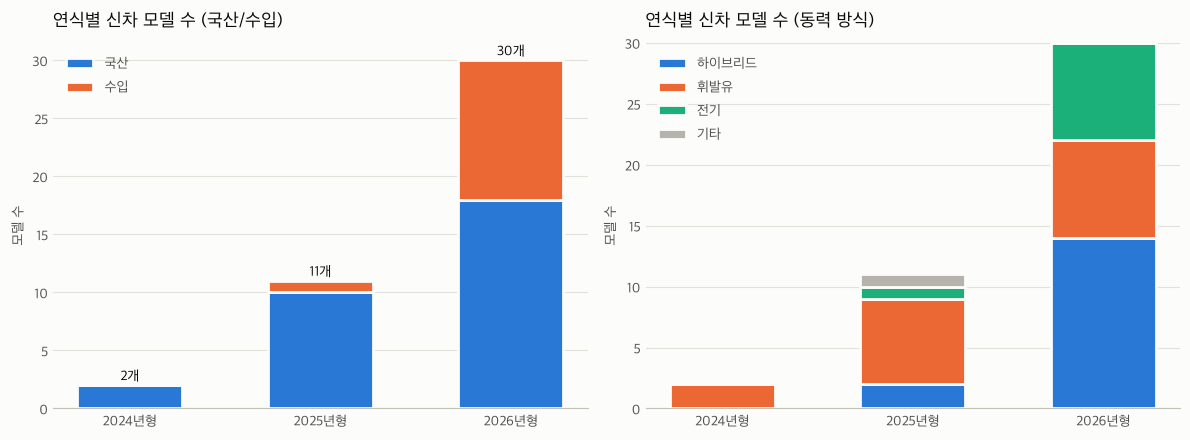

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), facecolor=SURFACE)
years = [2024, 2025, 2026]

# (왼쪽) 연식별 국산/수입
ax = axes[0]
dom = t1.loc[years, "국산"]; imp = t1.loc[years, "수입"]
x = [str(y) + "년형" for y in years]
ax.bar(x, dom, color=C_DOMESTIC, width=0.55, label="국산", edgecolor=SURFACE, linewidth=2)
ax.bar(x, imp, bottom=dom, color=C_IMPORT, width=0.55, label="수입", edgecolor=SURFACE, linewidth=2)
for i, y in enumerate(years):
    ax.text(i, dom[y] + imp[y] + 0.4, f"{dom[y] + imp[y]}개", ha="center", color=INK, fontsize=10)
style_ax(ax, "연식별 신차 모델 수 (국산/수입)", "모델 수")
ax.legend(frameon=False, loc="upper left", labelcolor=INK2)

# (오른쪽) 연식별 동력
ax = axes[1]
bottom = pd.Series(0, index=years)
for fuel in ["하이브리드", "휘발유", "전기", "기타"]:
    if fuel not in t2.columns:
        continue
    v = t2.loc[years, fuel]
    ax.bar(x, v, bottom=bottom, color=FUEL_COLORS[fuel], width=0.55, label=fuel, edgecolor=SURFACE, linewidth=2)
    bottom += v
style_ax(ax, "연식별 신차 모델 수 (동력 방식)", "모델 수")
ax.legend(frameon=False, loc="upper left", labelcolor=INK2)

plt.tight_layout()
plt.show()

## 6-3. 뉴스로 본 신차 출시 (연도별)

카테크 뉴스(질문 4의 방법)에서 **신차·출시 기사**를 연도별로 세어 봄. 2024년 기사는 사이트에 없음.

In [27]:
news_new = articles[articles["제목"].str.contains(NEW_CAR_WORDS)].copy()
news_new[["브랜드", "국산/수입"]] = news_new["제목"].apply(find_brand)
news_new = news_new.dropna(subset=["브랜드"])
news_new["연도"] = news_new["날짜"].dt.year
news_new["전기차"] = (news_new["제목"] + " " + news_new["요약"]).str.contains("전기|일렉트릭|EV|i5|iX|GV90")

t4 = pd.crosstab(news_new["연도"], news_new["국산/수입"]).reindex([2024, 2025, 2026], fill_value=0)
t4["그중 전기차"] = news_new.groupby("연도")["전기차"].sum().reindex(t4.index, fill_value=0).astype(int)
t4["합계"] = t4["국산"] + t4["수입"]
t4   # 2024년은 기사 자체가 없고, 2025년 기사는 신차 소식이 아닌 칼럼·시승기뿐

국산/수입,국산,수입,그중 전기차,합계
연도,,,,
2024,0,0,0,0
2025,0,0,0,0
2026,5,11,5,16


## 6-4. 실제 구매는? (판매·등록 통계)

카테크에는 판매 데이터가 없어서, 기사에 인용된 공식 통계를 직접 입력함.

| 수치 | 출처 |
|---|---|
| 2024 전기차 146,734대, 수입 비중 36% | [KAMA 결산(다음)](https://v.daum.net/v/6t7Eb62udR), [카가이](https://www.carguy.kr/news/articleView.html?idxno=54617) |
| 2025 전기차 220,177대, 국산 57.2% / 수입 42.8% | [KAMA 결산(네이트)](https://m.news.nate.com/view/20260120n32586), [한국경제](https://www.hankyung.com/article/2026012023091) |
| 2026년 1~9월 전기차 국산 167,312 / 수입 132,582, 9월은 수입 57.2% | [유카포스트](https://www.yuccapostkorea.com/news/articleView.html?idxno=2859) |
| 2025 신규 등록 169.5만 대 (휘발유 64.8만, 하이브리드 59.2만, 전기 22.1만, LPG 13.6만, 경유 8.6만) | [뉴시스](https://mobile.newsis.com/view/NISX20260128_0003493411) |
| 2026 상반기 신규 등록 85.7만 대 (하이브리드 29.2만, 휘발유 27.6만, 전기 19.9만, LPG 6.3만, 경유 2.1만) | [전자신문](https://www.etnews.com/20260730000002), [서울경제](https://www.sedaily.com/article/20073573) |

※ 2024년 국산/수입 대수는 '수입 비중 36%'로 계산한 값. 2024년 연료별 신규 등록은 찾지 못함.

In [28]:
ev_sales = pd.DataFrame({
    "기간": ["2024년", "2025년", "2026년 1~9월"],
    "전기차 판매(대)": [146734, 220177, 167312 + 132582],
    "국산(대)": [round(146734 * 0.64), round(220177 * 0.572), 167312],
    "수입(대)": [round(146734 * 0.36), round(220177 * 0.428), 132582],
})
ev_sales["수입 비중(%)"] = (ev_sales["수입(대)"] / ev_sales["전기차 판매(대)"] * 100).round(1)
ev_sales

,기간,전기차 판매(대),국산(대),수입(대),수입 비중(%)
0,2024년,146734,93910,52824,36.0
1,2025년,220177,125941,94236,42.8
2,2026년 1~9월,299894,167312,132582,44.2


In [29]:
# 연료별 신규 등록 (만 대)
reg = pd.DataFrame({
    "기간": ["2025년", "2026년 상반기"],
    "휘발유": [64.8, 27.6], "하이브리드": [59.2, 29.2], "전기": [22.1, 19.9], "LPG·경유": [13.6 + 8.6, 6.3 + 2.1],
}).set_index("기간")
reg_share = (reg.div(reg.sum(axis=1), axis=0) * 100).round(1)
print("[연료별 신규 등록 비중 %]")
reg_share

[연료별 신규 등록 비중 %]


,휘발유,하이브리드,전기,LPG·경유
기간,,,,
2025년,38.5,35.2,13.1,13.2
2026년 상반기,32.4,34.3,23.4,9.9


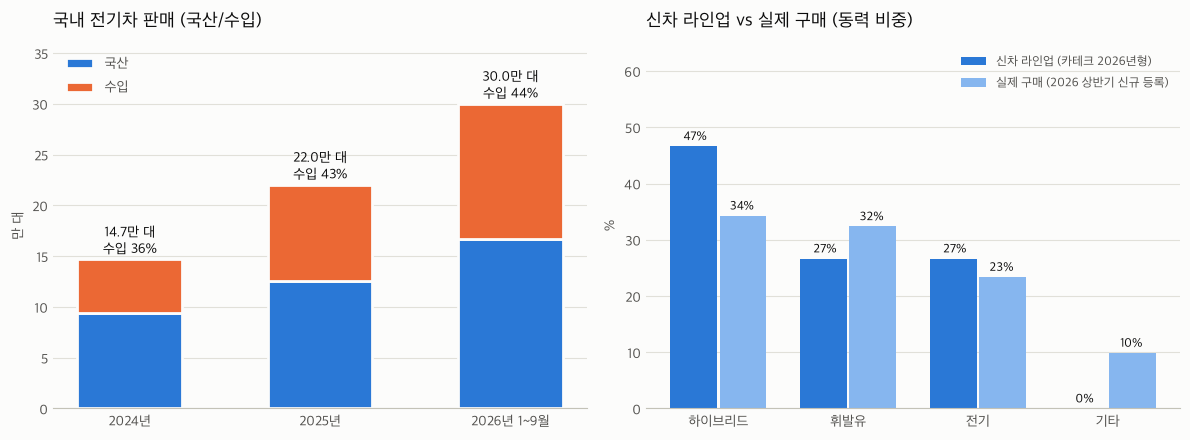

,신차 라인업 (카테크 2026년형),실제 구매 (2026 상반기 신규 등록)
하이브리드,46.7,34.3
휘발유,26.7,32.4
전기,26.7,23.4
기타,0.0,9.9


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), facecolor=SURFACE)

# (왼쪽) 전기차 판매: 국산 vs 수입
ax = axes[0]
x = ev_sales["기간"]
ax.bar(x, ev_sales["국산(대)"] / 10000, color=C_DOMESTIC, width=0.55, label="국산", edgecolor=SURFACE, linewidth=2)
ax.bar(x, ev_sales["수입(대)"] / 10000, bottom=ev_sales["국산(대)"] / 10000, color=C_IMPORT, width=0.55,
       label="수입", edgecolor=SURFACE, linewidth=2)
for i, r in ev_sales.iterrows():
    ax.text(i, r["전기차 판매(대)"] / 10000 + 0.6, f"{r['전기차 판매(대)'] / 10000:.1f}만 대\n수입 {r['수입 비중(%)']:.0f}%",
            ha="center", color=INK, fontsize=10)
style_ax(ax, "국내 전기차 판매 (국산/수입)", "만 대")
ax.set_ylim(0, 36)
ax.legend(frameon=False, loc="upper left", labelcolor=INK2)

# (오른쪽) 신차 라인업(2026년형) 동력 비중 vs 실제 신규 등록(2026 상반기) 비중
ax = axes[1]
supply = target[target["연식"] == 2026]["동력"].value_counts(normalize=True) * 100
demand = reg_share.loc["2026년 상반기"].rename({"LPG·경유": "기타"})
cats = ["하이브리드", "휘발유", "전기", "기타"]
comp = pd.DataFrame({"신차 라인업 (카테크 2026년형)": supply.reindex(cats).fillna(0),
                     "실제 구매 (2026 상반기 신규 등록)": demand.reindex(cats).fillna(0)})
w = 0.36
pos = range(len(cats))
ax.bar([p - w / 2 - 0.01 for p in pos], comp.iloc[:, 0], width=w, color=C_DOMESTIC, label=comp.columns[0])
ax.bar([p + w / 2 + 0.01 for p in pos], comp.iloc[:, 1], width=w, color="#86b6ef", label=comp.columns[1])
for p, (a, b) in zip(pos, comp.values):
    ax.text(p - w / 2, a + 1, f"{a:.0f}%", ha="center", color=INK, fontsize=9)
    ax.text(p + w / 2, b + 1, f"{b:.0f}%", ha="center", color=INK, fontsize=9)
ax.set_xticks(list(pos)); ax.set_xticklabels(cats)
style_ax(ax, "신차 라인업 vs 실제 구매 (동력 비중)", "%")
ax.set_ylim(0, 65)
ax.legend(frameon=False, loc="upper right", labelcolor=INK2, fontsize=9)

plt.tight_layout()
plt.show()
comp.round(1)

## 6-5. 인사이트

| # | 발견 | 근거 |
|---|---|---|
| 1 | **신차는 2026년형에 몰려 있고, 수입 신차가 급증** | 2024~2026년형 43개 중 2026년형 30개. 수입 비중 2025년형 9% → **2026년형 40%** |
| 2 | **전기차 신차는 수입이 주도** | 전기차 모델 9개 중 수입 6개 (테슬라·폭스바겐 각 2, BYD·폴스타 각 1) / 국산 3개 (기아 2, 현대 1). 뉴스 속 전기차 신차 기사 5개 중 4개가 수입 |
| 3 | **신차의 중심은 오히려 하이브리드** | 2026년형 동력: 하이브리드 47% > 휘발유·전기 각 27%. 국산 브랜드(기아·현대)가 특히 하이브리드 위주 |
| 4 | **전기차 구매는 빠르게 늘고 있음** | 전기차 판매 14.7만(2024) → 22.0만(2025) → **9개월 만에 30.0만**(2026)으로 이미 작년 전체를 넘음. 신규 등록 중 전기차 비중 13%(2025) → **23%(2026 상반기)** |
| 5 | **구매도 수입 쪽으로 이동** | 전기차 수입 비중 36% → 43% → 44%, 2026년 9월엔 **57%로 첫 역전**. 테슬라·중국산이 견인(2025년 중국산 전기차 33.9%) |
| 6 | **신차 vs 구매 차이** | 하이브리드는 라인업(47%)보다 구매(34%)가 적고, 휘발유는 라인업(27%)보다 구매(32%)가 많음 → 신차는 친환경차로 옮겨가는데, 소비자는 아직 휘발유차도 많이 삼 |
| 7 | **업계 뉴스와 소비자 관심의 차이** | 카테크 뉴스는 신차·브랜드 소식 위주, 화재·충전·보조금 기사는 사실상 0개 (질문 3·5) |

## 6-6. 한계와 보완할 점

| 한계 | 왜 문제인가 | 보완 방법 |
|---|---|---|
| 카테크 라인업은 **렌트 상품 목록(인기 차종 62개)** | 실제로 출시된 모든 신차가 아님. 2024년형이 2개뿐인 것도 구형이 목록에서 빠졌기 때문 (지금 남아 있는 차만 보임) | 다나와·제조사 발표 등 **출시 일정 데이터**로 연도별 전체 신차 수집 |
| 연식 ≠ 출시 연도 | 2026년형이 2025년에 나오기도 함 | 출시일(발표일) 기준으로 다시 집계 |
| 뉴스는 탭마다 최신 약 16개만 보임 | 2024년 기사 없음, 오래된 기간은 적게 잡힘 | 매일 수집해서 쌓기 (스케줄 실행) |
| 기사 출처가 **모터트렌드 한 곳** | 신차·홍보 위주로 치우침 | 일반 언론(사회·경제면)과 커뮤니티 데이터 추가 |
| 판매·등록 통계는 **기사 속 숫자를 직접 입력** | 원자료가 아니고, 2024년 국산/수입은 비율로 계산한 값, 2024년 연료별 등록은 없음 | KAMA·KAIDA 월별 자료, 국토부 통계누리 원자료 다운로드 |
| 기간이 서로 다름 | 2026년은 1~9월(판매)·상반기(등록)라 연간과 직접 비교 주의 | 연말 통계 나오면 다시 비교 |
| 라인업 비중(**모델 수**) vs 구매 비중(**대수**) | 단위가 달라 '차이'는 방향만 참고 | 모델별 판매량을 붙여서 대수 기준으로 비교 |
| 단어(키워드)로 분류 | 잘못 분류될 수 있음 (실제로 GV80·애스턴마틴 오분류를 고친 적 있음) | 결과를 사람이 확인, 분류 기준 보완 |
| 커뮤니티 원문을 직접 못 모음 | 소비자 반응은 기사·글을 통한 간접 정보 | 허용된 방법으로 커뮤니티 게시글 수집 |

## 6-7. 소비자들이 우려하는 점 (질문 5 웹 검색 기준)

| 우려 | 내용 |
|---|---|
| 🔥 **화재** | 전기차 화재 2021년 24건 → 2025년 98건 → **2026년 상반기만 73건**. 한 번 나면 끄기 어렵고 피해가 큼 (단, 전기차 대수 증가도 반영된 수치) |
| 🅿️ **지하주차장·충전 갈등** | 청라 화재 이후 지하 주차·충전 금지 규약, 충전기 지상 이전 → 차주와 이웃 간 갈등 |
| ⚡ **충전요금 인상** | 초급속 13% 인상(393원/kWh), 아파트 민간 충전기 요금 인상 불만 → "유지비가 싸다"는 장점이 줄어듦 |
| 💰 **보조금 조기 소진** | 국비 8월 말 90% 소진, 지자체 추가 공고도 빨리 마감 → 사는 시기에 따라 가격 차이 큼 |
| 🔧 **중고값·배터리·리콜** | 되팔 때 값이 모델·배터리 상태에 따라 크게 다름, 리콜·정비 대기 |
| 🌏 **수입·중국산 A/S** | 수입 비중이 커지면서 정비망·부품 수급 걱정 |
| ❄️ **겨울 주행거리·충전 불편** | 겨울엔 주행거리 감소, 집에서 충전 못 하면 불편하다는 차주 후기 |

→ **정리**: 신차는 수입 전기차·하이브리드 중심으로 쏟아지고 전기차 구매도 늘고 있지만, 소비자는 **안전(화재)·충전·비용(보조금·요금·중고값)**을 걱정하고 있음. 업계 뉴스(카테크)는 이 걱정을 거의 다루지 않으므로, 살 때는 질문 5의 체크리스트로 직접 확인하는 것이 필요함.